Markov state sequence:
[0, np.int64(0), np.int64(1), np.int64(2), np.int64(2), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(2), np.int64(1), np.int64(2), np.int64(3), np.int64(3), np.int64(2), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(3), np.int64(2), np.int64(2), np.int64(2), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(0)]


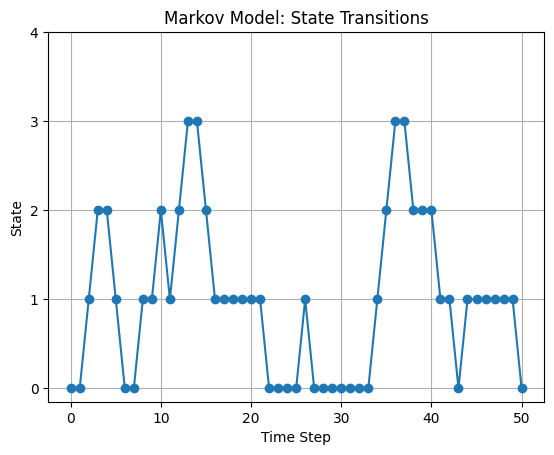

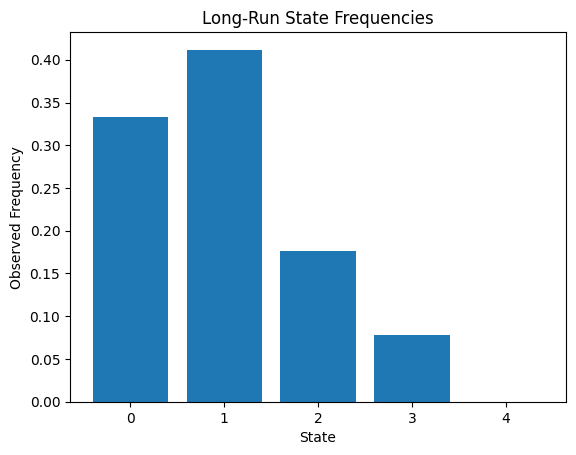


Q-table:
[[ 3.11  4.58]
 [ 3.12  6.2 ]
 [ 4.57  8.  ]
 [ 6.19 10.  ]
 [ 0.    0.  ]]

Learned policy:
State 0: RIGHT
State 1: RIGHT
State 2: RIGHT
State 3: RIGHT


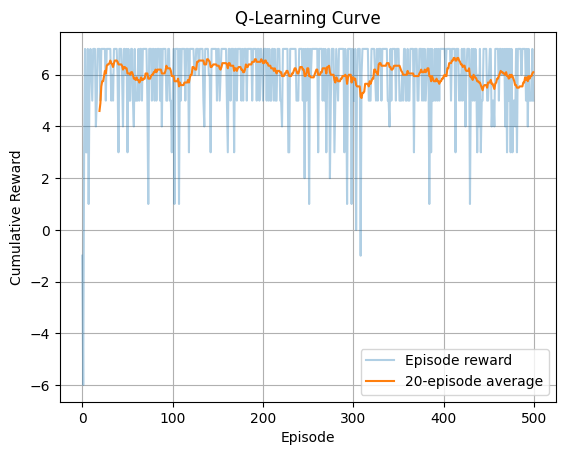

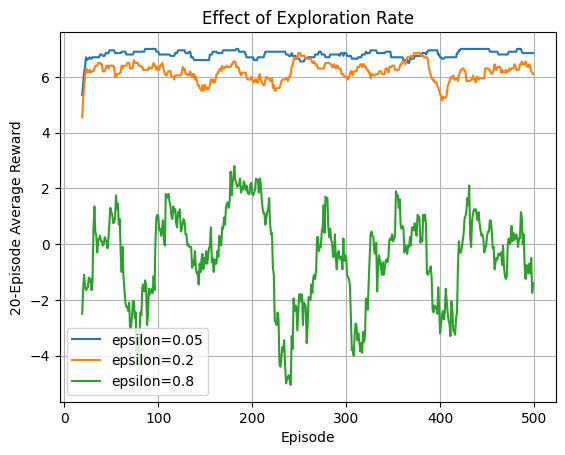

Gamma=0.1: Policy=[np.int64(1), np.int64(1), np.int64(1), np.int64(1)]
Gamma=0.5: Policy=[np.int64(1), np.int64(1), np.int64(1), np.int64(1)]
Gamma=0.9: Policy=[np.int64(1), np.int64(1), np.int64(1), np.int64(1)]
Gamma=0.99: Policy=[np.int64(1), np.int64(1), np.int64(1), np.int64(1)]


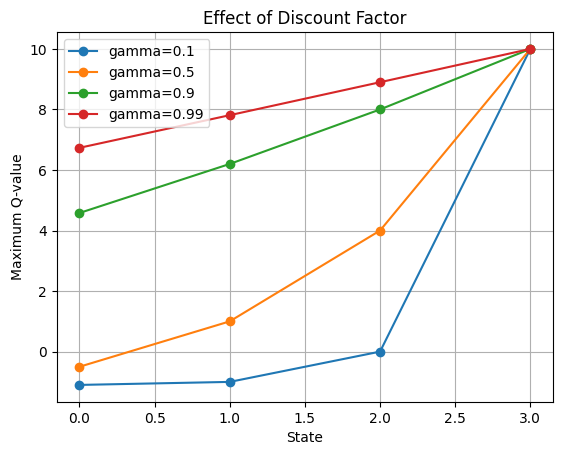


Policy evaluation:
Always LEFT average reward: -30.0
Always RIGHT average reward: 7.0


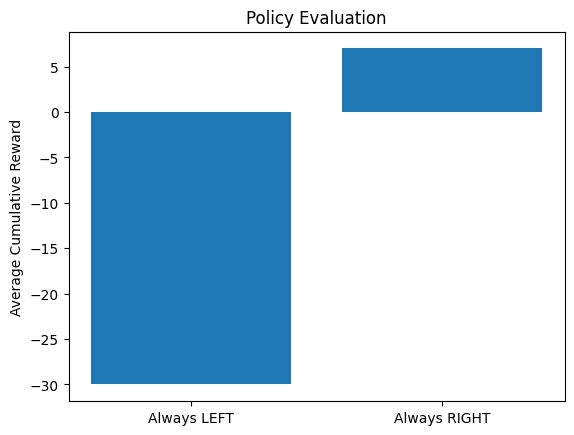

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. MARKOV MODEL
# ==========================================

np.random.seed(42)

states = [0, 1, 2, 3, 4]
goal = 4

# Transition probabilities: rows = current state,
# columns = next state.
P = np.array([
    [0.7, 0.3, 0.0, 0.0, 0.0],
    [0.2, 0.5, 0.3, 0.0, 0.0],
    [0.0, 0.2, 0.5, 0.3, 0.0],
    [0.0, 0.0, 0.2, 0.5, 0.3],
    [0.0, 0.0, 0.0, 0.0, 1.0]
])

state = 0
trajectory = [state]

for _ in range(50):
    state = np.random.choice(states, p=P[state])
    trajectory.append(state)

print("Markov state sequence:")
print(trajectory)

plt.figure()
plt.plot(trajectory, marker="o")
plt.xlabel("Time Step")
plt.ylabel("State")
plt.title("Markov Model: State Transitions")
plt.yticks(states)
plt.grid(True)
plt.show()

# Long-run state frequencies
counts = np.bincount(trajectory, minlength=5)
frequencies = counts / len(trajectory)

plt.figure()
plt.bar(states, frequencies)
plt.xlabel("State")
plt.ylabel("Observed Frequency")
plt.title("Long-Run State Frequencies")
plt.show()


# ==========================================
# 2 & 3. REWARD ENVIRONMENT AND Q-LEARNING
# ==========================================

n_states = 5
n_actions = 2

LEFT = 0
RIGHT = 1

def step(state, action):
    if action == LEFT:
        next_state = max(0, state - 1)
    else:
        next_state = min(goal, state + 1)

    if next_state == goal:
        reward = 10
    else:
        reward = -1

    done = next_state == goal
    return next_state, reward, done


def train_q_learning(episodes=500, alpha=0.1,
                     gamma=0.9, epsilon=0.2):
    Q = np.zeros((n_states, n_actions))
    episode_rewards = []

    for episode in range(episodes):
        state = 0
        total_reward = 0

        for _ in range(30):
            # Epsilon-greedy exploration
            if np.random.random() < epsilon:
                action = np.random.randint(n_actions)
            else:
                action = np.argmax(Q[state])

            next_state, reward, done = step(state, action)

            # Q-learning update
            if done:
                target = reward
            else:
                target = reward + gamma * np.max(Q[next_state])

            Q[state, action] += alpha * (
                target - Q[state, action]
            )

            total_reward += reward
            state = next_state

            if done:
                break

        episode_rewards.append(total_reward)

    return Q, episode_rewards


# Train a baseline agent
Q, rewards = train_q_learning(
    episodes=500,
    alpha=0.1,
    gamma=0.9,
    epsilon=0.2
)

print("\nQ-table:")
print(np.round(Q, 2))

action_names = ["LEFT", "RIGHT"]

print("\nLearned policy:")
for s in range(n_states - 1):
    print(f"State {s}: {action_names[np.argmax(Q[s])]}")

# Learning curve
plt.figure()
plt.plot(rewards, alpha=0.35, label="Episode reward")

# Moving average smooths out randomness
window = 20
if len(rewards) >= window:
    average = np.convolve(
        rewards, np.ones(window) / window, mode="valid"
    )
    plt.plot(
        range(window - 1, len(rewards)),
        average,
        label="20-episode average"
    )

plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.title("Q-Learning Curve")
plt.legend()
plt.grid(True)
plt.show()


# ==========================================
# 4. EXPLORATION VS EXPLOITATION
# ==========================================

plt.figure()

for eps in [0.05, 0.2, 0.8]:
    _, episode_rewards = train_q_learning(
        episodes=500,
        alpha=0.1,
        gamma=0.9,
        epsilon=eps
    )

    window = 20
    average = np.convolve(
        episode_rewards,
        np.ones(window) / window,
        mode="valid"
    )

    plt.plot(
        range(window - 1, len(episode_rewards)),
        average,
        label=f"epsilon={eps}"
    )

plt.xlabel("Episode")
plt.ylabel("20-Episode Average Reward")
plt.title("Effect of Exploration Rate")
plt.legend()
plt.grid(True)
plt.show()


# ==========================================
# 5. EFFECT OF DISCOUNT FACTOR
# ==========================================

plt.figure()

for g in [0.1, 0.5, 0.9, 0.99]:
    Qg, _ = train_q_learning(
        episodes=500,
        alpha=0.1,
        gamma=g,
        epsilon=0.2
    )

    policy = [
        np.argmax(Qg[s]) for s in range(n_states - 1)
    ]

    print(f"Gamma={g}: Policy={policy}")

    plt.plot(
        range(n_states - 1),
        np.max(Qg[:goal], axis=1),
        marker="o",
        label=f"gamma={g}"
    )

plt.xlabel("State")
plt.ylabel("Maximum Q-value")
plt.title("Effect of Discount Factor")
plt.legend()
plt.grid(True)
plt.show()


# ==========================================
# 6. SIMPLE POLICY EVALUATION
# ==========================================

# Compare the always-left and always-right policies.
def evaluate_policy(action, runs=100):
    returns = []

    for _ in range(runs):
        state = 0
        total_reward = 0

        for _ in range(30):
            state, reward, done = step(state, action)
            total_reward += reward

            if done:
                break

        returns.append(total_reward)

    return np.mean(returns)


left_score = evaluate_policy(LEFT)
right_score = evaluate_policy(RIGHT)

print("\nPolicy evaluation:")
print("Always LEFT average reward:", left_score)
print("Always RIGHT average reward:", right_score)

plt.figure()
plt.bar(
    ["Always LEFT", "Always RIGHT"],
    [left_score, right_score]
)
plt.ylabel("Average Cumulative Reward")
plt.title("Policy Evaluation")
plt.show()
